# 10. Solvent: The Environment Matters

Every calculation demonstrated so far had been performed in **gas phase**. We are modelling a single molecule in a vacuum. That is not the real world. Reactions occur at air pressure, at somewhat sane temperatures (generally less than 200&nbsp;&deg;C) and in **solvent**.

## Solvent Models

A charged system will be very high in energy in a **vacuum** but may be perfectly stable in **water**, where dipoles can arrange to oppose the charge and relax the system. Solvent can have many effects. Protic solvents can assist the reaction by interacting **directly** with the reactants. Solvents might serve as an acid or a base **catalyst**, for example. Solvents can form structured **cages** around reactants and affect the outcome of very fast reactions.

But the biggest effect will be **stabilization** of charges by dipole-dipole interactions. There is a lot to think about for solvent effects and so models that adjust the energies of the calculation by including solvent effects can be **quite complex**. We can include the molecules of the solvent in our ***ab initio*** calculations, we could model the solvent using **molecular mechanics** to account for its random motion but still involve its presence when atoms become near enough to the reactant to be included in *ab initio* methods. These methods will be costly.

A common method that is less costly is to treat solvent like an electric field. This is the **continuum model**. The solvent is mathematically modelled as a field that **interacts** with the molecule being modelled. There are many options and we will be using the popular PCM continuum model.

## The \$PCM Group

The PCM model can be included in the *GAMESS* calculation by adding a `$PCM` group. There are many **parameters** that can be included but we will use it without any changes by simply declaring the `SOLVNT` parameter.

```text
 $PCM SOLVNT = WATER $END
```
There are many solvent **options**. See the [*GAMESS* documentation](https://www.msg.chem.iastate.edu/gamess/documentation.html) for more information. Other **popular** choices are WATER, CH3OH, BENZENE, C6H12, THF and DMSO.

We could **repeat** any exercise that we have performed so far by adding the `$PCM` group to the input files. The results would likely be a little different, but not in an important way. Nothing we have tried so far involves **charged** systems. The effect of solvent will be most obvious relative to gas phase if we use ions.

We will **set up** a transition state for an *S<sub>N</sub>2* reaction and **optimize** it in a polar **solvent** and in **gas phase**. Then we will run an IRC calculation and compare the two reaction coordinates. Every job is run from this notebook with *Python*, and *Python* also does the copying and pasting between files that used to be done by hand in a text editor.

:::{note} Mac users: after a restart
macOS resets the shared-memory limits every time you restart. If a *GAMESS* job stops with a fatal error and the `.log` file shows `shmget returned an error`, set the limits again (see [Raise shared-memory limits](#shared-memory-limits) in [](1D-CompileInstruction2024.md)).
:::

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` and `.dat` files are written into the `runs/ch9/` folder next to this notebook. That is the folder to look in when you open a result in *MacMolPlt*.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import gamess_tools as gt

INPUTS = Path("inputs/ch9") # input files for this chapter
RUNS = Path("runs/ch9")     # where log files and new input files are written
RUNS.mkdir(parents=True, exist_ok=True)
gt.RUN_FOLDER = RUNS        # run_gamess() writes its files here

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
PCM_WATER = " $PCM SOLVNT = WATER $END\n"
# ========================================================================

## Setting Up the IRC

Symmetry makes life easy. If we consider chloride **reacting** with methyl chloride in an *S<sub>N</sub>2* manner, we will have a *D<sub>3h</sub>* structure. I will try to set it up using my understanding of the coordinate space used by *GAMESS* and the **nature** of the *D<sub>3h</sub>* point group.

```{figure} images/Solvent_1.png
---
width: 450px
name: fig9_1
---
*A symmetrical S<sub>N</sub>2 reaction.*
```

There will be only **three** unique atoms. The primary axis in *GAMESS* is the *z*-axis. The carbon will be at the **origin** and the chloride will be on the *z*-axis. It will be **reflected** down to the other side along the *z*-axis by the symmetry to give the second chloride. The primary *&sigma;<sub>v</sub>* plane is the *xz* plane. The unique C-H bond will lie **along** the *x*-axis and the two other hydrogens will be **positioned** by symmetry in the other two *&sigma;<sub>v</sub>* planes within the *xy* *&sigma;<sub>h</sub>* plane.

```{figure} images/Solvent_2.png
---
width: 450px
name: fig9_2
---
*The S<sub>N</sub>2 transition state placed in the coordinate space of GAMESS.*
```

### The Input Files

Our first input file will be in the gas phase. I used the B3LYP DFT **method** by including `DFTTYP=B3LYP` in the `$CONTRL` group. I picked the 3-21G **basis set** (probably a poor choice, but I wanted to finish the calculation quickly). I set up a `$ZMAT` group for automatic generation of redundant **internal coordinates** so that I can read bond distances and angles out of the text file. The `NONVDW` options are to make sure that both C-Cl bonds are **included** in the auto generation even if they are **too long** to fit the definition of a bond.

The **unique** coordinates will be 0,0,0 for **carbon**, 1,0,0 for the unique **hydrogen** and 0,0,2 for the unique **chloride**. I know that C-H bonds are generally about 1&nbsp;&angst; and a typical C-Cl bond is 1.7&nbsp;&angst; so I chose 2&nbsp;&angst; since the bonds should be breaking and forming. Nobody knows the true values, but some people think that they can be calculated. The whole system will have a **charge** of -1.

In [2]:
print((INPUTS / "SN2_321_U.inp").read_text())

 $CONTRL SCFTYP=ROHF RUNTYP=OPTIMIZE DFTTYP=B3LYP MAXIT=30 
    ICHARG=-1 MULT=1 COORD=UNIQUE NZVAR=12 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $DATA 
SN2
DNH 3

Cl    17.0    0.00000     0.00000     2.00000
C     6.0     0.00000     0.00000     0.00000
H     1.0     1.00000     0.00000     0.00000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=1,3, 2,3 $END



The transition state must, by symmetry, be **defined** by the *D<sub>3h</sub>* point group. So I don't have to constrain anything. The C-Cl bonds will be **forced** to be identical by the symmetry requirements. As long as they don't fly away to infinity, we should get something that looks like an *S<sub>N</sub>2* transition state.

The second input file will be a **copy** of the first. All I will do is **add** the `$PCM` group for a **solvent**. I will choose water. The file `inputs/ch9/SN2_H2O_321_U.inp` comes with the book, but the cell below shows that it really is the gas-phase file plus one line.

In [3]:
gas_text = (INPUTS / "SN2_321_U.inp").read_text().splitlines()
water_text = (INPUTS / "SN2_H2O_321_U.inp").read_text().splitlines()

print("Lines in the water input that are not in the gas-phase input:")
print([line for line in water_text if line not in gas_text])

Lines in the water input that are not in the gas-phase input:
[' $PCM SOLVNT = WATER $END']


### Initial Results

Run both optimizations. The gas-phase job takes a few seconds and the solvent job a minute or two.

In [4]:
gas_opt = gt.run_gamess(INPUTS / "SN2_321_U.inp")
water_opt = gt.run_gamess(INPUTS / "SN2_H2O_321_U.inp")

SN2_321_U: finished normally (SN2_321_U.log)


SN2_H2O_321_U: finished normally (SN2_H2O_321_U.log)


The last occurrence of `NSERCH` usually occurs at the **final optimized structure**, and the list of internal coordinates there gives the bond distances (the angles are defined by the point group and will be perfect, by definition). *Python* does the looking. First, did each job find a stationary point? *GAMESS* prints `EQUILIBRIUM GEOMETRY LOCATED` when it does.

In [5]:
for log in (gas_opt, water_opt):
    found = bool(gt.grep("EQUILIBRIUM GEOMETRY LOCATED", log))
    steps = gt.nserch_energies(log)
    print(f"{log.name:22s} steps: {len(steps):3d}   last E = {steps[-1][1]:.10f}   located: {found}")

SN2_321_U.log          steps:   7   last E = -955.6090406225   located: True
SN2_H2O_321_U.log      steps:  41   last E = -955.7061419988   located: False


Now the C–H and C–Cl bond lengths in the final structures. Atoms 1 and 2 are the chlorides, atom 3 is the carbon and atoms 4 to 6 are the hydrogens (look at the list of all atoms in the log file). What are the C-H and C-Cl bond lengths?

In [6]:
for log in (gas_opt, water_opt):
    atoms = gt.final_geometry(log)
    print(log.name)
    print(f"   C-Cl1 = {gt.distance(atoms, 3, 1):.4f} Å    C-Cl2 = {gt.distance(atoms, 3, 2):.4f} Å")
    print("   C-H   = " + ",  ".join(f"{gt.distance(atoms, 3, h):.4f}" for h in (4, 5, 6)) + " Å")

SN2_321_U.log
   C-Cl1 = 2.3843 Å    C-Cl2 = 2.3843 Å
   C-H   = 1.0738,  1.0738,  1.0738 Å
SN2_H2O_321_U.log
   C-Cl1 = 1.9213 Å    C-Cl2 = 3.5227 Å
   C-H   = 1.0863,  1.0863,  1.0879 Å


```{note}
I had used *C<sub>3h</sub>* symmetry in my first attempts while learning how to do this. What can I say, point groups are not my thing. As a result the calculation completed in both cases but gave an incorrect structure for the solvent job. We are actually optimizing a saddle point here and *GAMESS* will try to escape downhill unless the symmetry makes an air-tight constraint.
```

The gas-phase calculation gives two identical C–Cl distances: a *D<sub>3h</sub>* structure that looks like the transition state. The water calculation is different. It may settle down near the *D<sub>3h</sub>* structure for a few steps, but it **keeps fighting** that answer. The gradient never finds a low value that would end the calculation as the structure **thrashes** around the saddle point. Eventually it falls over the edge and breaks symmetry to find a structure that appears to be the **starting materials**/products: one short C–Cl bond and one long one. It **failed** to find a transition state-like structure, and it ran out of steps (`NSTEP=40`) without locating anything. Plot the energy of each step to watch it happen.

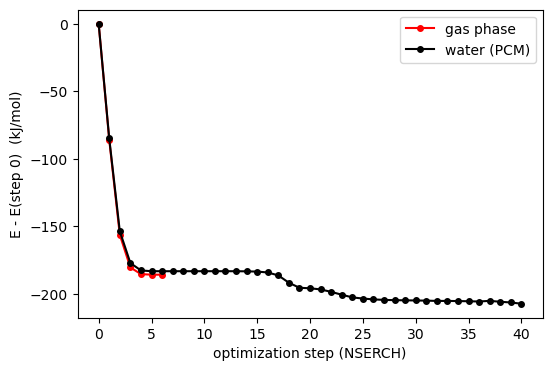

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for log, colour, label in ((gas_opt, "r", "gas phase"), (water_opt, "k", "water (PCM)")):
    steps = gt.nserch_energies(log)
    e0 = steps[0][1]
    ax.plot([s for s, e in steps], [(e - e0) * HARTREE_TO_KJMOL for s, e in steps],
            colour + "o-", label=label, markersize=4)
ax.set(xlabel="optimization step (NSERCH)", ylabel="E - E(step 0)  (kJ/mol)")
ax.legend()
plt.show()

### Hessian Calculations

I will **take** the coordinates from the **gas phase** optimization where the *D<sub>3h</sub>* symmetry held up and use them in **both** new calculations for vibrational analysis, with and without solvent. If **imaginary vibrations** are found then I will copy in the vibrational data (the `$HESS` group from the .dat files) and perform the saddle point optimization.

So I **copied** in the coordinates, **changed** to `RUNTYP=HESSIAN` and ran the jobs. They failed again and again. Eventually I read the error information at the end of the file. It stated that the system was unable to create a derivative of at least one of the needed functions. It then **suggested** that I change `METHOD=ANALYTIC` to `METHOD=SEMINUM` in the `$FORCE` group. When you can't get a derivative by using **calculus**, you can still get it **using numeric** methods.

In this notebook `gt.new_input()` does the copying. It takes the optimization input, swaps in the **symmetry unique** atoms of the optimized structure, changes the run type and adds a `$GUESS` and a `$FORCE` group just before `$DATA`. The solvent version is then the gas-phase Hessian file with the `$PCM` group added.

In [8]:
hess_groups = (" $GUESS GUESS=HUCKEL $END\n"
               " $FORCE METHOD=SEMINUM VIBANL=.TRUE. $END\n"
               " $DATA")

gas_hess_inp = gt.new_input(
    INPUTS / "SN2_321_U.inp", RUNS / "SN2_D3h_321G_HESS.inp",
    atoms=gt.final_geometry(gas_opt, unique=True),
    replacements={"RUNTYP=OPTIMIZE": "RUNTYP=HESSIAN", " $DATA": hess_groups})

water_hess_inp = gt.new_input(
    gas_hess_inp, RUNS / "SN2_D3h_H2O_321G_HESS.inp",
    replacements={" $DATA": PCM_WATER + " $DATA"})

print(water_hess_inp.read_text())

 $CONTRL SCFTYP=ROHF RUNTYP=HESSIAN DFTTYP=B3LYP MAXIT=30 
    ICHARG=-1 MULT=1 COORD=UNIQUE NZVAR=12 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $GUESS GUESS=HUCKEL $END
 $FORCE METHOD=SEMINUM VIBANL=.TRUE. $END
 $PCM SOLVNT = WATER $END
 $DATA 
SN2
DNH 3

 CL      17.0    0.0000000000   -0.0000000000    2.3842905263
 C        6.0   -0.0000000000    0.0000000000   -0.0000000000
 H        1.0    1.0737765083    0.0000000000   -0.0000000000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=1,3, 2,3 $END



Observe how the two Hessian input files **differ** only by the presence of the `$PCM` group. Now run them. Each one takes a minute or two. I was using a very small basis set so you can imagine that this job might take hours with a higher level of theory. Let us hope that the 3-21G basis set is enough for this task.

In [9]:
gas_hess = gt.run_gamess(gas_hess_inp)
water_hess = gt.run_gamess(water_hess_inp)

for log in (gas_hess, water_hess):
    print(f"{log.name:28s} wall time {gt.wall_time(log):6.1f} s")

SN2_D3h_321G_HESS: finished normally (SN2_D3h_321G_HESS.log)


SN2_D3h_H2O_321G_HESS: finished normally (SN2_D3h_H2O_321G_HESS.log)
SN2_D3h_321G_HESS.log        wall time    6.8 s
SN2_D3h_H2O_321G_HESS.log    wall time   16.5 s


The results revealed an imaginary vibration in both files. The frequencies are in a block of results near the end of the Hessian log file. Below is the start of that block for the gas phase.

In [10]:
gt.excerpt(gas_hess, "FREQUENCIES IN CM**-1", before=6, after=19, occurrence=0)

 3018   --- SYMMETRY FOR NORMAL MODES ---
 3019   INCLUDING TRANSLATION AND ROTATION
 3020      2*A1'    0*A1"    3*A2'    6*A2"    7*E''   10*E'  
 3021   EXCLUDING TRANSLATION AND ROTATION (SAYVETZ < 0.01)
 3022      2*A1'    0*A1"    0*A2'    1*A2"    0*E''    4*E'  
 3023  
 3024       FREQUENCIES IN CM**-1, IR INTENSITIES IN DEBYE**2/AMU-ANGSTROM**2,
 3025       REDUCED MASSES IN AMU.
 3026  
 3027                              1           2           3           4           5
 3028         FREQUENCY:       207.30 I     28.09        8.07        3.43        2.19  
 3029          SYMMETRY:         A2"         A2'         E'          E''         E'  
 3030      REDUCED MASS:     13.20895     1.01511    16.26866    21.20918    18.17195
 3031      IR INTENSITY:     19.94752     0.00000     0.00001     0.00020     0.00002
 3032  
 3033    1   CL           X -0.00024042 -0.00016392  0.02390422  0.08918834  0.03907593
 3034                     Y -0.00000030 -0.00202219  0.13898455 -0.05936

Look at the first column. There is a frequency labelled with an `I` after the number. The "I" indicates an **imaginary frequency**. We might say that it has a negative frequency, and `gt.frequencies()` returns it that way. Below it are the vectors for **motion** of each atom in the vibration. We can see that there is motion along the *z*-axis for the C and both Cl atoms. Both chlorides are moving a small amount in one direction (let us say "left") and the central carbon is moving about six times as much in the other direction (to the "right"). The **carbon** is the **lightest** of these atoms and will take on the **largest** motion in this vibration. One bond is getting **shorter** and one is getting **longer**. This is consistent with the outcome of the reaction. We have **found** the imaginary vibration that aligns with the transition state.

Is it the same in water? The cell below lists the lowest frequencies of both calculations. The first six (near zero) are translations and rotations.

In [11]:
for log in (gas_hess, water_hess):
    freqs = gt.frequencies(log)
    imaginary = [f for f in freqs if f < 0]
    print(f"{log.name:28s} imaginary: {imaginary}   next lowest: {sorted(freqs)[1:4]}")

SN2_D3h_321G_HESS.log        imaginary: [-207.3]   next lowest: [2.19, 2.4, 3.43]
SN2_D3h_H2O_321G_HESS.log    imaginary: [-345.51]   next lowest: [0.03, 0.06, 0.09]


**Both** log files show a single imaginary vibration. In water it has a larger magnitude: the solvent makes the top of the energy barrier sharper. I used *MacMolPlt* to visualize the vibration as shown in {numref}`fig9_3`. Open `runs/ch9/SN2_D3h_321G_HESS.log` in *MacMolPlt* to see it yourself.

```{figure} images/Solvent_3.png
---
width: 450px
name: fig9_3
---
*The imaginary vibration for the gas-phase Hessian calculation. The solvent calculation gave similar results.*
```
We are now **ready** to set up the saddle point calculation.

### Saddle Point Calculations

**Take** the Hessian input file and **change** the `RUNTYP` to `SADPOINT`. Then **track down** the .dat file of the Hessian job and **cut and paste** the `$HESS` group into the new input file. The .dat files are in `runs/ch9/` and two helpers do the work:

- `gt.dat_group(dat_file, "$HESS")` copies the `$HESS` group out of a .dat file, and
- `gt.add_group(input_file, text, new_file)` pastes it at the end of an input file.

`RUNTYP=SADPOINT` reads the `$HESS` group automatically (`HESS=READ` is its default in `$STATPT`).

```{note}
You must use the `$HESS` group from the solvent run for the solvent saddle point. The vibrations for gas phase, although similar, are not the same.
```

In [12]:
def saddle_input(hess_inp, hess_log, new_file):
    # The Hessian input with RUNTYP=SADPOINT and the $HESS group pasted in.
    sadl = gt.new_input(hess_inp, new_file,
                        replacements={"RUNTYP=HESSIAN": "RUNTYP=SADPOINT"})
    hess = gt.dat_group(hess_log.with_suffix(".dat"), "$HESS")
    return gt.add_group(sadl, hess)

gas_sadl_inp = saddle_input(gas_hess_inp, gas_hess, RUNS / "SN2_D3h_321G_SADL.inp")
water_sadl_inp = saddle_input(water_hess_inp, water_hess, RUNS / "SN2_D3h_H2O_321G_SADL.inp")

# show the top of the solvent file: everything up to the first few $HESS lines
print("\n".join(water_sadl_inp.read_text().splitlines()[:24]))
print(" ...\n Many More Lines...")

 $CONTRL SCFTYP=ROHF RUNTYP=SADPOINT DFTTYP=B3LYP MAXIT=30 
    ICHARG=-1 MULT=1 COORD=UNIQUE NZVAR=12 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $GUESS GUESS=HUCKEL $END
 $FORCE METHOD=SEMINUM VIBANL=.TRUE. $END
 $PCM SOLVNT = WATER $END
 $DATA 
SN2
DNH 3

 CL      17.0    0.0000000000   -0.0000000000    2.3842905263
 C        6.0   -0.0000000000    0.0000000000   -0.0000000000
 H        1.0    1.0737765083    0.0000000000   -0.0000000000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=1,3, 2,3 $END
 $HESS
ENERGY IS     -955.6969584957 E(NUC) IS      107.7130904090
 1  1 7.24722963E-03 4.72776858E-09 1.40751904E-03 1.64032681E-03 6.23237211E-09
 1  2-3.73062421E-05-1.28704263E-02 3.56697299E-09-5.72539939E-04 6.79441987E-04
 1  3-8.50832562E-04 3.79570682E-03 6.79439886E-04 8.50829417E-04 3.79570827E-03
 1  4 2.62230604E-03 2.22564304E-10-8.38683706E-03
 ...
 Many More Lines...


Now the two input files **differ** by having different `$HESS` groups and by whether a `$PCM` group is present to declare **solvent**. Run them.

In [13]:
gas_sadl = gt.run_gamess(gas_sadl_inp)
water_sadl = gt.run_gamess(water_sadl_inp)

SN2_D3h_321G_SADL: finished normally (SN2_D3h_321G_SADL.log)


SN2_D3h_H2O_321G_SADL: finished normally (SN2_D3h_H2O_321G_SADL.log)


## Running the IRC

We now have data for optimized saddle points of **both gas-phase and solvent** conditions.

### Analyzing the TS structures

Below are the coordinates for the **two results**, printed from the line `SADDLE POINT LOCATED` onwards.

In [14]:
gt.excerpt(gas_sadl, "SADDLE POINT LOCATED", after=14)

 1477        ***** SADDLE POINT LOCATED *****
 1478   COORDINATES OF SYMMETRY UNIQUE ATOMS (ANGS)
 1479     ATOM   CHARGE       X              Y              Z
 1480   ------------------------------------------------------------
 1481   CL         17.0   0.0000000000  -0.0000000000   2.3842905263
 1482   C           6.0  -0.0000000000   0.0000000000  -0.0000000000
 1483   H           1.0   1.0737765083   0.0000000000  -0.0000000000
 1484   COORDINATES OF ALL ATOMS ARE (ANGS)
 1485     ATOM   CHARGE       X              Y              Z
 1486   ------------------------------------------------------------
 1487   CL         17.0   0.0000000000   0.0000000000  -2.3842905263
 1488   CL         17.0   0.0000000000  -0.0000000000   2.3842905263
 1489   C           6.0  -0.0000000000   0.0000000000  -0.0000000000
 1490   H           1.0  -0.5368882541   0.9299177342   0.0000000000
 1491   H           1.0  -0.5368882542  -0.9299177342   0.0000000000


In [15]:
gt.excerpt(water_sadl, "SADDLE POINT LOCATED", after=9)

 1891        ***** SADDLE POINT LOCATED *****
 1892   COORDINATES OF ALL ATOMS ARE (ANGS)
 1893     ATOM   CHARGE       X              Y              Z
 1894   ------------------------------------------------------------
 1895   CL         17.0   0.0000240609  -0.0000000004  -2.3912433939
 1896   CL         17.0   0.0000539071  -0.0000000002   2.3907346011
 1897   C           6.0  -0.0001082121  -0.0000000588   0.0011965208
 1898   H           1.0  -0.5383474069   0.9310013616   0.0003691779
 1899   H           1.0  -0.5383478701  -0.9310011484   0.0003691617
 1900   H           1.0   1.0752784580   0.0000005078   0.0026686499


We immediately see that, while the **gas phase** system maintained the *D<sub>3h</sub>* symmetry (only the symmetry unique atoms are printed first, then all atoms), the **solvent** calculation again broke symmetry: there is no list of symmetry unique atoms and the coordinates are not quite zero where they should be. It was held at the saddle point by the math of the saddle point calculation, but was clearly fighting to twist out of the *D<sub>3h</sub>* shape. How far from symmetric is it?

In [16]:
for log in (gas_sadl, water_sadl):
    atoms = gt.final_geometry(log)
    r1, r2 = gt.distance(atoms, 3, 1), gt.distance(atoms, 3, 2)
    print(f"{log.name:26s} C-Cl1 = {r1:.4f} Å   C-Cl2 = {r2:.4f} Å   "
          f"difference = {100 * abs(r1 - r2) / r1:.3f} %   E = {gt.final_energy(log):.10f}")

SN2_D3h_321G_SADL.log      C-Cl1 = 2.3843 Å   C-Cl2 = 2.3843 Å   difference = 0.000 %   E = -955.6090406225
SN2_D3h_H2O_321G_SADL.log  C-Cl1 = 2.3924 Å   C-Cl2 = 2.3895 Å   difference = 0.121 %   E = -955.6969739956


The motions that broke symmetry are very small. **Perhaps** starting with the gas phase structure and applying a solvent Hessian calculation resulted in a bad start. **Perhaps** the solvent environment breaks the symmetry (it is modelling a "cavity" that may not fit the *D<sub>3h</sub>* point group).

### Read the Documentation

I **looked up** the [documentation](https://www.msg.chem.iastate.edu/gamess/GAMESS_Manual/docs-references.txt) and see that **PCM methods ignore symmetry**. So the symmetry lock is not present when using the `$PCM` group. The transition state in the solvent calculation is almost perfectly symmetrical and the small perturbations away from *D<sub>3h</sub>* are within the error induced by bond vibrations. We are about 0.1&nbsp;% away from perfect *D<sub>3h</sub>* in the C–Cl distances.

There are **other solvent models** that may respect symmetry (I would actually have to look them up and learn about them) but we will **stick with PCM** here.

### Build the Input Files

To be fair, I will **not use symmetry** with the gas phase calculation. I will use the `C1` symmetry setting and the full set of Cartesian **coordinates** in the IRC input files. I will have to again track down the `$HESS` groups from the .dat files for the saddle point calculations and paste them into the respective input files for IRC.

We **copy** a previous IRC input file (from the [Diels Alder project](8A_Diels_Alder.ipynb)) and **add** in the coordinates from the results above for each case. We add the `$PCM` group for the solvent input file. Then we **paste** in the appropriate `$HESS` group from the corresponding .dat file.

The recipe looks like this...

1. Take a previous input file
2. Swap out the coordinates
3. Add a `$PCM` group if needed
4. Swap out the `$HESS` group

```{note}
Once you get used to working with text files you will find that it is often faster to modify them, by hand or with a few lines of *Python*, than to plod through the menus of a GUI tool to do the same thing.
```

In this case, I am **calculating** the orbitals, so I will not need the `$VEC` group from the .dat files and I am using **auto** generation of internal coordinates so I will not need the IZMAT matrix in the `$ZMAT` group.

The book comes with the two IRC input files, without their `$HESS` groups. Here is the gas-phase one. The `$IRC` group asks for up to 300 points (`NPOINT`), each a stride of 0.30&nbsp;bohr&middot;amu<sup>&frac12;</sup> along the path, starting at a saddle point (`SADDLE=.TRUE.`) whose energy should be calculated first (`TSENGY=.TRUE.`).

In [17]:
print((INPUTS / "SN2_D3h_321G_IRC.inp").read_text())

 $CONTRL SCFTYP=ROHF RUNTYP=IRC DFTTYP=B3LYP MAXIT=30 
    ICHARG=-1 MULT=1 COORD=UNIQUE NZVAR=12 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30 
      SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
 $GUESS GUESS=HUCKEL $END
 $FORCE METHOD=SEMINUM VIBANL=.TRUE. $END
 $DATA 
SN2
C1
 CL         17.0   0.0000000000   0.0000000000  -2.3842905066
 CL         17.0   0.0000000000  -0.0000000000   2.3842905066
 C           6.0   0.0000000000   0.0000000000   0.0000000000
 H           1.0  -0.5368882526   0.9299177315   0.0000000000
 H           1.0  -0.5368882526  -0.9299177315   0.0000000000
 H           1.0   1.0737765052  -0.0000000000  -0.0000000000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=1,3, 2,3 
 $END



The cell below follows the recipe: it swaps in **all** the atoms of the located saddle point (the `C1` point group needs every atom) and pastes the `$HESS` group from the saddle point .dat file. Each run must be done **again** after **changing** `FORWRD=.TRUE.` to `FORWRD=.FALSE.` to go the other direction along the IRC, so the cell writes that copy too. The solvent template already holds the `$PCM` group.

In [18]:
def irc_inputs(template, sadl_log, name):
    # Forward and reverse IRC inputs: saddle point atoms + its $HESS group.
    forward = gt.new_input(template, RUNS / f"{name}.inp",
                           atoms=gt.final_geometry(sadl_log))
    gt.add_group(forward, gt.dat_group(sadl_log.with_suffix(".dat"), "$HESS"))
    reverse = gt.new_input(forward, RUNS / f"{name}_R.inp",
                           replacements={"FORWRD=.TRUE.": "FORWRD=.FALSE."})
    return forward, reverse

gas_irc_inps = irc_inputs(INPUTS / "SN2_D3h_321G_IRC.inp", gas_sadl, "SN2_D3h_321G_IRC")
water_irc_inps = irc_inputs(INPUTS / "SN2_D3h_H2O_321G_IRC.inp", water_sadl, "SN2_D3h_H2O_321G_IRC")

print("\n".join(water_irc_inps[1].read_text().splitlines()[:26]))
print(" ...\n Many More Lines...")

 $CONTRL SCFTYP=ROHF RUNTYP=IRC DFTTYP=B3LYP MAXIT=30 
    ICHARG=-1 MULT=1 COORD=UNIQUE NZVAR=12 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30 
      SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.FALSE. NPOINT=300 $END
 $GUESS GUESS=HUCKEL $END
 $FORCE METHOD=SEMINUM VIBANL=.TRUE. $END
 $PCM SOLVNT = WATER $END
 $DATA 
SN2
C1
 CL      17.0    0.0000240609   -0.0000000004   -2.3912433939
 CL      17.0    0.0000539071   -0.0000000002    2.3907346011
 C        6.0   -0.0001082121   -0.0000000588    0.0011965208
 H        1.0   -0.5383474069    0.9310013616    0.0003691779
 H        1.0   -0.5383478701   -0.9310011484    0.0003691617
 H        1.0    1.0752784580    0.0000005078    0.0026686499
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=1,3, 2,3 
 $END
 $HESS
ENERGY IS     -955.6969739956 E(NUC) IS      107.4285283876
 1  1 6.95543782E-03 3.42992459E-09 9.55860805E-04 1.93857948E-03 1.7

Now run all **four** IRC calculations. This is the long step of the chapter: each run takes two to five minutes, so expect to wait about a quarter of an hour. Each run stops by itself when it reaches the bottom of the valley, long before the 300 points we allowed.

In [19]:
irc_logs = {}
for inp in (*gas_irc_inps, *water_irc_inps):
    irc_logs[inp.stem] = gt.run_gamess(inp)

SN2_D3h_321G_IRC: FAILED, see /Users/blink/github/UsingGAMESSv2/runs/ch9/SN2_D3h_321G_IRC.log


SN2_D3h_321G_IRC_R: FAILED, see /Users/blink/github/UsingGAMESSv2/runs/ch9/SN2_D3h_321G_IRC_R.log


SN2_D3h_H2O_321G_IRC: finished normally (SN2_D3h_H2O_321G_IRC.log)


SN2_D3h_H2O_321G_IRC_R: finished normally (SN2_D3h_H2O_321G_IRC_R.log)


Did they work? `run_gamess()` probably reported that the **gas phase** runs FAILED. Do not panic. An IRC run has to decide when it has reached the bottom of the valley, and *GAMESS* has two ways of doing that. Either the gradient becomes smaller than `OPTTOL` and the run ends normally, or the energy of a new point comes out **higher** than the last one. Then *GAMESS* prints `YOU MAY JUST HAVE PASSED THROUGH A MINIMUM` and stops with an error, even though all the points calculated before are perfectly good. The cell below checks which way each run ended.

In [20]:
for name, log in irc_logs.items():
    if gt.grep("GRADIENT IS BELOW -OPTTOL-", log):
        reason = "gradient below OPTTOL (normal end)"
    elif gt.grep("PASSED THROUGH A MINIMUM", log):
        reason = "energy went up: passed through a minimum"
    else:
        reason = "something else: read the end of the log file!"
    print(f"{name:24s} {reason}")

SN2_D3h_321G_IRC         energy went up: passed through a minimum
SN2_D3h_321G_IRC_R       energy went up: passed through a minimum
SN2_D3h_H2O_321G_IRC     gradient below OPTTOL (normal end)
SN2_D3h_H2O_321G_IRC_R   gradient below OPTTOL (normal end)


All four calculations reached a minimum, so all four are **successful**. Keep the gas phase result in mind: its energy started to go back up. We will come back to it.

## Interpretation of IRC Results

Below are the **animations** of the reaction coordinate using *MacMolPlt* for both IRC calculations. As demonstrated in the [Diels-Alder exercise](8A_Diels_Alder.ipynb), I **loaded** in the .log file for one of the IRC results and then **appended** frames using the second file that used the **reverse** direction. I then **annotated** the bond lengths and **exported** the animation. You can do the same with the log files in `runs/ch9/`.

Compare the two IRC profiles below. In the solvent IRC, the C-Cl distance to the departing chloride is much longer at the end than in the gas phase IRC. In the "products", the gas phase profile keeps the chloride closer and the remaining C-Cl bond is longer. The energy minimum is also much higher than in the solvent case (don't trust the values with these low level methods, but the relative magnitudes are instructive). In gas phase, the lowest energy **complex** is actually slightly along the reaction coordinate to the transition state. Chloride anion in a **vacuum** is very high in energy and **pushing** electron density into the back of the methyl chloride results in a charge-transfer complex with some of the negative charge now being **shared** on the chloride of the methyl chloride. Sharing the charge lowers the energy even though bonds are "starting" to change. Gas phase is an **extreme** environment and charged species will be **very high** in energy here.

```{figure} images/SN2_2.gif
---
width: 500px
name: fig9_5
---
*The IRC result for gas phase*
```

```{figure} images/SN2_H2O_2.gif
---
width: 500px
name: fig9_6
---
*The IRC result for solvent*
```

The numbers behind the animations are in the log files. `gt.irc_points()` reads the stride, energy and the two C–Cl distances of each point on the path. The cell below prints the **ends** of each path: the last point of the forward and of the reverse run.

In [21]:
for name, log in irc_logs.items():
    points = gt.irc_points(log, bonds=[(1, 3), (2, 3)])
    end = points[-1]
    print(f"{name:24s} {len(points):3d} points   end: stride {end['stride']:5.2f}   "
          f"C-Cl1 = {end['R(1,3)']:.3f} Å   C-Cl2 = {end['R(2,3)']:.3f} Å   "
          f"E - E(TS) = {(end['energy'] - points[0]['energy']) * HARTREE_TO_KJMOL:6.1f} kJ/mol")

SN2_D3h_321G_IRC           9 points   end: stride  2.09   C-Cl1 = 2.734 Å   C-Cl2 = 2.095 Å   E - E(TS) =   -3.7 kJ/mol
SN2_D3h_321G_IRC_R        10 points   end: stride  2.09   C-Cl1 = 2.095 Å   C-Cl2 = 2.734 Å   E - E(TS) =   -3.7 kJ/mol
SN2_D3h_H2O_321G_IRC      18 points   end: stride  4.85   C-Cl1 = 3.111 Å   C-Cl2 = 1.958 Å   E - E(TS) =  -23.2 kJ/mol
SN2_D3h_H2O_321G_IRC_R    18 points   end: stride  4.94   C-Cl1 = 1.958 Å   C-Cl2 = 3.111 Å   E - E(TS) =  -23.2 kJ/mol


### The Ground State

What is the calculated C-Cl **bond length** in the methyl chloride starting material? We can quickly modify the input file that we used for the transition state search. All we need to do is **change** the point group. The transition state was *D<sub>3h</sub>* and methyl chloride is *C<sub>3v</sub>*. That change alone (together with removing the second chloride's charge and its `NONVDW` bond) will give us the methyl chloride arrangement. Below are the **two input files** for this calculation. Compare them to the files at the start of the chapter.

In [22]:
print((INPUTS / "SN2_C3V_CH3Cl.inp").read_text())
print((INPUTS / "SN2_C3V_H2O_CH3Cl.inp").read_text())

 $CONTRL SCFTYP=ROHF RUNTYP=OPTIMIZE DFTTYP=B3LYP MAXIT=30 
    ICHARG=-0 MULT=1 COORD=UNIQUE NZVAR=9 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $DATA 
methyl Chloride
CNV 3

Cl    17.0    0.00000     0.00000     2.00000
C     6.0     0.00000     0.00000     0.00000
H     1.0     1.00000     0.00000     0.00000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. $END

 $CONTRL SCFTYP=ROHF RUNTYP=OPTIMIZE DFTTYP=B3LYP MAXIT=30 
    ICHARG=-0 MULT=1 COORD=UNIQUE NZVAR=9 $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $PCM SOLVNT = WATER $END
 $DATA 
methyl Chloride
CNV 3

Cl    17.0    0.00000     0.00000     2.00000
C     6.0     0.00000     0.00000     0.00000
H     1.0     1.00000     0.00000     0.00000
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. $END



In [23]:
gas_ch3cl = gt.run_gamess(INPUTS / "SN2_C3V_CH3Cl.inp")
water_ch3cl = gt.run_gamess(INPUTS / "SN2_C3V_H2O_CH3Cl.inp")

for log in (gas_ch3cl, water_ch3cl):
    atoms = gt.final_geometry(log)          # atom 1 is Cl, atom 2 is C
    print(f"{log.name:24s} C-Cl = {gt.distance(atoms, 1, 2):.3f} Å   "
          "C-H = " + ", ".join(f"{gt.distance(atoms, 2, h):.4f}" for h in (3, 4, 5)) + " Å")

SN2_C3V_CH3Cl: finished normally (SN2_C3V_CH3Cl.log)


SN2_C3V_H2O_CH3Cl: finished normally (SN2_C3V_H2O_CH3Cl.log)
SN2_C3V_CH3Cl.log        C-Cl = 1.902 Å   C-H = 1.0868, 1.0868, 1.0868 Å
SN2_C3V_H2O_CH3Cl.log    C-Cl = 1.920 Å   C-H = 1.0862, 1.0862, 1.0862 Å


In the results we again see the slight off-symmetry of the PCM result: the three C–H bonds are not exactly equal. Without symmetry being enforced it will not be perfect but it is within 0.01&nbsp;% of *C<sub>3v</sub>* symmetry.

The key observation is that in methyl chloride, the C-Cl bond calculated **in solvent** is 1.92&nbsp;&angst;. The solvent IRC settles down to a ground state with the two C-Cl distances being 1.96&nbsp;&angst; and 3.12&nbsp;&angst; (see the table of IRC end points above). This is very much like a chloride and a methyl chloride. **In water**, the chloride ion is much **more stable** on its own and will be able to relax to a fully non-bonding distance.

In **gas-phase**, the calculated C-Cl length in methyl chloride is 1.90&nbsp;&angst;. In the IRC, the ground state was reached with C-Cl lengths of 2.10&nbsp;&angst; and 2.73&nbsp;&angst;. We have a bond that is significantly **longer** than the covalent C-Cl distance for methyl chloride and the other is significantly **shorter** than a non-bonded distance.

### Conclusion

We can conclude that the solvent model made a **large difference**. This fact will be made even more obvious if we visualize the data by plotting it.

## Plotting Results

*MacMolPlt* produces an energy plot, but we can make other **plots** easily using *Python*. The first thing that I need is a **table** of the two C–Cl bond lengths and the energy for each point on the IRC path. The .log file is enormous. How can I get my data quickly?

### Processing the Data

We need to **isolate** the lines that contain the **information** that we want. We want to **collect** the following information&hellip;

- The step number
- The "stride" value (representative of the overall change between steps)
- The energy at that step
- The two C-Cl internal coordinates

Each datum is on a line with recognizable **text**:

| Datum | Text on the line |
| :--- | :--- |
| stride | `AT PATH DISTANCE STOTAL` |
| energy | `TOTAL ENERGY` (the line that ends in `HARTREE`) |
| first C–Cl distance | `STRETCH   1  3` (carbon is atom 3, the chlorides are atoms 1 and 2) |
| second C–Cl distance | `STRETCH   2  3` |

`gt.irc_points()` searches for exactly these lines and keeps the numbers together point by point. Here are the first lines that it searches for in the solvent forward run, found with `gt.grep()`:

In [24]:
log = irc_logs["SN2_D3h_H2O_321G_IRC"]
for text in ("AT PATH DISTANCE STOTAL", "TOTAL ENERGY            =", "STRETCH   1  3", "STRETCH   2  3"):
    lines = gt.grep(text, log)
    print(f"{len(lines):3d} lines with '{text}', the first two:")
    print("\n".join(lines[:2]))

 17 lines with 'AT PATH DISTANCE STOTAL', the first two:
          AT PATH DISTANCE STOTAL =   0.29996     SQRT(AMU)-BOHR
          AT PATH DISTANCE STOTAL =   0.59989     SQRT(AMU)-BOHR
 17 lines with 'TOTAL ENERGY            =', the first two:
          TOTAL ENERGY            =  -955.6971679 HARTREE
          TOTAL ENERGY            =  -955.6977168 HARTREE
 18 lines with 'STRETCH   1  3', the first two:
   1 STRETCH   1  3                     4.5210559       2.3924399
   1 STRETCH   1  3                     4.6146976       2.4419930
 18 lines with 'STRETCH   2  3', the first two:
   2 STRETCH   2  3                     4.5155722       2.3895381
   2 STRETCH   2  3                     4.4221926       2.3401237


```{warning}
There is one more `STRETCH` line of each kind than there are `STOTAL` and `TOTAL ENERGY` lines. This is because step zero (the transition state) has a stride of zero (not explicitly reported, but obvious when you think about it) and the energy for step zero is the saddle point energy, which is reported with the text `FINAL RO-B3LYP ENERGY` on a line near the beginning of the .log file. `gt.irc_points()` takes care of this for you.
```

### Cleaning the Data

The forward and reverse halves of each IRC must now be **cleaned and collated** into a nice neat table. I could use a text editor to do this. I could paste the data into Microsoft Excel and organize it that way. But I will use a *Jupyter* notebook. That way I can also provide detailed **documentation** in both text and code that others can follow when interpreting my work.

The process of building the table is best **presented** in the notebooks themselves. You can **download** the notebooks using the link at the top right corner of this web book.

In the [first notebook](10_Solvent_IRC_Plots.ipynb) we clean and collate the data. Then we save the data tables for future use. In the [second notebook](10_Solvent_IRC_Plots-Data.ipynb) we import the tables and plot some data.

First we must **decide** what to plot. Below are some ideas. The plots are drawn by the second notebook from your own results.

### Comparing IRC Plots

The stride value should be similar for each since it is the same bonds in both cases that are changing (stride is a composite value that encompasses the totality of bond changes). How do the energies **compare** in gas phase vs. water as bonds break and form across the transition state? Let us plot the **relative energy** vs. **stride**.

![](#fig-irc-energy)

In the gas phase, the **relative energy** between the ground state and the transition state is **much smaller**. This is because the **negatively charged** chloride nucleophile/leaving group is very **high in energy** in a **vacuum** where it cannot share its electrons. In the **solvent** model, the energy is less as chloride can be stabilized by the **electric dipole** of water. In fact the gas phase IRC ends early because the **energy** is actually about to start **going back up** as the nucleophile moves away. In a vacuum, chloride separated widely from the methyl chloride is actually **higher in energy** than the ion–molecule complex.

### Comparing More O'Ferrall–Jencks Plots

The famous More O'Ferrall–Jencks plot follows one **coordinate** of the reaction with respect to **another**. This reaction has a **nucleophile** that moves in to make a bond and a **leaving group** that departs, breaking a bond. We could plot "making" on one axis and "breaking" on the other.

There are **two** C-Cl distances in each IRC: the **incoming** nucleophile and the departing leaving group. The C-Cl bond in methyl chloride is calculated to be about 1.9&nbsp;&angst;. The incoming nucleophile starts at a longer distance and **moves** in. The leaving group bond will begin to break. At the transition state, they should be identical (defined by symmetry). Let us plot **one** length against the **other**. Will it be a straight line? Will it be a curve?

![](#fig-irc-bonds)

The black line is the **solvent** IRC. What would you call that? I vote for "double ended hockey stick". It is clear that, at the beginning, **most** of the stride score is due to the nucleophile **moving in** towards the carbon. Only when it has come a good part of the way in do we see the leaving group **start to move** in concert. Would you say that the reaction "begins" when the nucleophile **reaches** that point? Does it end when the leaving group reaches that distance on the **other side**? Or should we include the translation of the nucleophile in from farther away?

The **gas phase** IRC is shorter because of the high cost of moving the chloride away in a vacuum. The key takeaway here is that solvent modeling has a **very large effect** in charged systems and probably a significant effect in every system.

### The 3<sup>rd</sup> Dimension

We can use a 3D plot to combine the information in the two previous plots above. Below is a 3D plot of the solvent IRC. Does that help you to imagine the nucleophile translating in, the making and breaking of bonds, and the leaving group translating away? I wonder what other kinds of plots we could use.

![](#fig-irc-3d)

## Summary

Adding the **solvent model** made a huge difference in the energy of the reaction. The IRC for *S<sub>N</sub>2* was familiar to us when modelled in **water** but was not when modelled in **gas phase**.

In the **solvent model**, the system moves to lower energy as the chloride **leaves** into the pool of mathematical water. We can easily imagine **separate** chloride and methyl chloride that meet and react.

In **gas phase**, the chloride is not stabilized and is high in energy when it is alone. To relax its electron density it is actually the lowest energy state to have a **partial bond** to the carbon of methyl chloride and, consequently, to have the C-Cl bond in methyl chloride **partially broken**. This is a state that we would consider to be "on the way" to reacting and not a ground state. But we are familiar with solvent reactions, not gas phase.

**Gas phase is not the same as solvent**. Should we redo everything that we did up until now by adding a `$PCM` group to all our input files and running them again? That will be left as an exercise for the reader.

## A Challenge

Is the rotational energy profile of **butane** different in water and cyclohexane solvents compared to gas phase? My hypothesis is that there will be little difference.

Is the rotational energy profile of **butadiene** different in water and cyclohexane solvents compared to gas phase? My hypothesis is that there will be a detectable, but not large difference. We do have large changes in electronic structure as the &pi; system changes with rotation but no charges are involved.

Is the IRC of the **Diels-Alder** reaction different in water and cyclohexane solvents compared to gas phase? I think this would respond similarly to the butadiene rotation for the same reasons. But we could be surprised. Go try it.

Modify the butane rotational energy profile by using **ethylene glycol**. Does the energy at different torsional values change between water, cyclohexane and gas phase?

Modify the butadiene rotational energy profile by using **glyoxal**. Does the energy at different torsional values change between water, cyclohexane and gas phase?

Are the energies (Eigenvalues) and coefficients (Eigenvectors) of **molecular orbitals** different when solvent is applied? Model **butadiene** in the *s-trans* conformer and see. Then do the same with **acrolein**.

```{tip}
Adding a solvent to an existing input file is one line of *Python*:
`gt.new_input(old_file, new_file, replacements={" $DATA": " $PCM SOLVNT=C6H12 $END\n $DATA"})`.
`gt.molecular_orbitals(log_file)` returns the orbital energies and coefficients for comparison.
```

## AI Statement

This page was converted from the original Markdown page `9_Solvent.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 80 %).** The discussion of solvent models, the `$PCM` group, the set-up of the *D<sub>3h</sub>* transition state, the story of the failed solvent optimization, the switch to `METHOD=SEMINUM`, the saddle point and IRC recipe, the interpretation of the IRCs, the plot discussions, the summary and the challenge are the author's words, as are all figures, animations and input files. Small edits: typos fixed, the gas-phase C–Cl length of methyl chloride is now 1.90&nbsp;&angst; (the original said 1.92&nbsp;&angst;, the solvent value), *S<sub>N</sub>2* markup repaired, the description of the imaginary mode and the size of the symmetry error now match the numbers printed by the code, and the ground-state bond lengths are those of the runs in this notebook.
- **Written by AI.** The settings cell, all code cells and the sentences that introduce them; the optimization energy plot; the frequency and symmetry checks; the functions `saddle_input()` and `irc_inputs()`; the check of how each IRC run ended (the gas-phase runs stop with an error message when the energy rises); the table of IRC end points; the *grep*-to-*Python* table; the tip in the challenge; and the helpers `add_group()` and `irc_points()` in `gamess_tools.py`.
- **Changed workflow.** Jobs are run with `run_gamess()`; the Hessian, saddle point and reverse IRC inputs are written by *Python* (coordinates from the log files, `$HESS` groups from the .dat files) instead of by copy and paste; *grep* and the shell script `processIRC.sh` are replaced by `gt.irc_points()`; and the plots are embedded from the plotting notebook, so they show your own results.
- **Comparisons removed.** At the author's request, sentences and shell scripts that compared each step with the previous book's terminal and text-editor workflow were removed or rewritten, so the page reads as written for *Python*.